In [1]:
# %pip install mne
import pandas as pd
import numpy as np
import mne
import matplotlib.pyplot as plt

In [2]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [3]:
def read_prep_eeg(eeg_file_path_vhdr, low_freq=None, high_freq=None):

    '''
    Read and preprocess raw data to get EEG channels x time samples dataframe

    '''
    
    raw = mne.io.read_raw_brainvision(eeg_file_path_vhdr, preload=True)
    channels = raw.ch_names[:63]
    
    raw.set_channel_types({
    "Mano DX": "misc",
    "Mano SX": "misc",
    "ECG": "ecg",
    "pressione": "misc"})
    
    if low_freq is not None or high_freq is not None:
        
        raw = raw.copy().filter(l_freq=low_freq, h_freq=high_freq)
        
    raw = raw.pick("eeg")
    #data_mean_subtracted = data - np.mean(data, axis=1, keepdims=True)
    #df = pd.DataFrame(data_mean_subtracted.T, columns=channels)
    
    return raw

In [4]:
# Read Smits11.vhdr file from the directory. File path is needed if file is not in the directory
file = "Smits11.vhdr"
raw = read_prep_eeg(file, low_freq = 1.0)

Extracting parameters from Smits11.vhdr...
Setting channel info structure...
Reading 0 ... 1524799  =      0.000 ...   304.960 secs...
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 16501 samples (3.300 s)



In [5]:
raw

<RawBrainVision | Smits11.eeg, 63 x 1524800 (305.0 s), ~733.0 MiB, data loaded>

In [6]:
sfreq = 5000
pre = int(0.020 * sfreq)   
post = int(0.100 * sfreq)
time_epoch = np.arange(-pre, post) /sfreq

def get_erp(raw, low_freq=None, high_freq=None):

    # Get events from annotations
    events, event_id = mne.events_from_annotations(raw)
    samples = events[:, 0]

    # Remove near-duplicate triggers
    clean = [samples[0]]
    for s in samples[1:]:
        if s - clean[-1] > 100:
            clean.append(s)

    triglist_clean = np.array(clean, dtype=np.int64)

    epochs = []
    for trigger in triglist_clean:
        if trigger - pre < 0 or trigger + post > raw.n_times:
            continue

        epoch, times = raw[:, trigger - pre: trigger + post]
        epochs.append(epoch)

    epochs = np.stack(epochs, axis=0)   # (n_epochs, n_channels, n_times)
    erp = np.mean(epochs, axis=0)       # (n_channels, n_times)

    # baseline window 11-14 ms after stimulus
    b_start = pre + int(0.011 * sfreq)
    b_end = pre + int(0.014 * sfreq)

    baseline = np.mean(erp[:, b_start:b_end], axis=1, keepdims=True)
    erp_corrected = erp - baseline

    return erp_corrected

In [7]:
erp_mean = get_erp(raw, low_freq=1.0)

Used Annotations descriptions: [np.str_('Response/R  7'), np.str_('Response/R 15')]


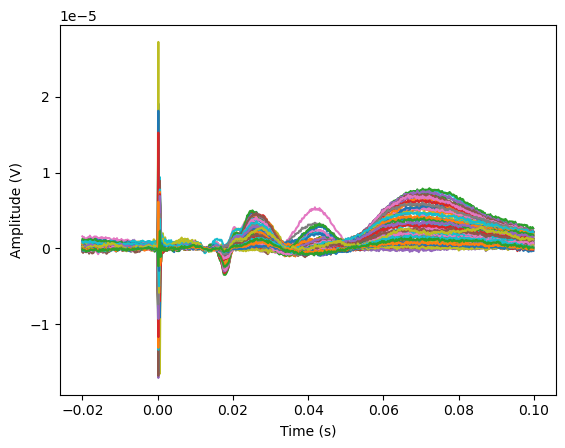

In [8]:
for i in range(63):
    plt.plot(time_epoch, erp_mean[i])

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (V)")
plt.show()

In [9]:
topo_grid_vals_global = None
topo_grid_vals_plot_global = None
topo_grid_times_global = None
topo_grid_channels_global = None

In [10]:
def plot_topographies(raw, tmin=None, tmax=None):
    global topo_grid_vals_global
    global topo_grid_vals_plot_global
    global topo_grid_times_global
    global topo_grid_channels_global

    info = raw.info.copy()
    picks = mne.pick_types(info, eeg=True)
    info = mne.pick_info(info, picks)

    montage = mne.channels.make_standard_montage("standard_1020")
    info.set_montage(montage, on_missing="ignore")

    if tmin is None:
        tmin_peak = 0.015
    else:
        tmin_peak = tmin

    if tmax is None:
        tmax_peak = 0.025
    else:
        tmax_peak = tmax

    time_mask = (time_epoch >= tmin_peak) & (time_epoch <= tmax_peak)
    time_idx = np.where(time_mask)[0]
    times_to_plot = time_epoch[time_idx]

    topo_grid_vals = []
    topo_grid_vals_plot = []

    n_maps = len(time_idx)
    n_cols = 5
    n_rows = int(np.ceil(n_maps / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3 * n_rows))
    axes = axes.ravel()

    for ax, idx, t in zip(axes, time_idx, times_to_plot):

        # 63 potenziali ERP grezzi a questo tempo
        topo_vals = erp_mean[:, idx]

        # valori effettivamente plottati
        topo_vals_to_plot = topo_vals / topo_vals.sum()

        # salvo i vettori
        topo_grid_vals.append(topo_vals.copy())
        topo_grid_vals_plot.append(topo_vals_to_plot.copy())

        im, cn = mne.viz.plot_topomap(
            topo_vals_to_plot,
            info,
            axes=ax,
            show=False,
            cmap="jet",
        )

        ax.set_title(f"{t * 1000:.1f} ms")
        plt.colorbar(im, ax=ax)

    for ax in axes[n_maps:]:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig("A.png")
    plt.show()

    # salvo globalmente
    topo_grid_vals_global = np.array(topo_grid_vals)
    topo_grid_vals_plot_global = np.array(topo_grid_vals_plot)
    topo_grid_times_global = times_to_plot.copy()
    topo_grid_channels_global = info.ch_names.copy()

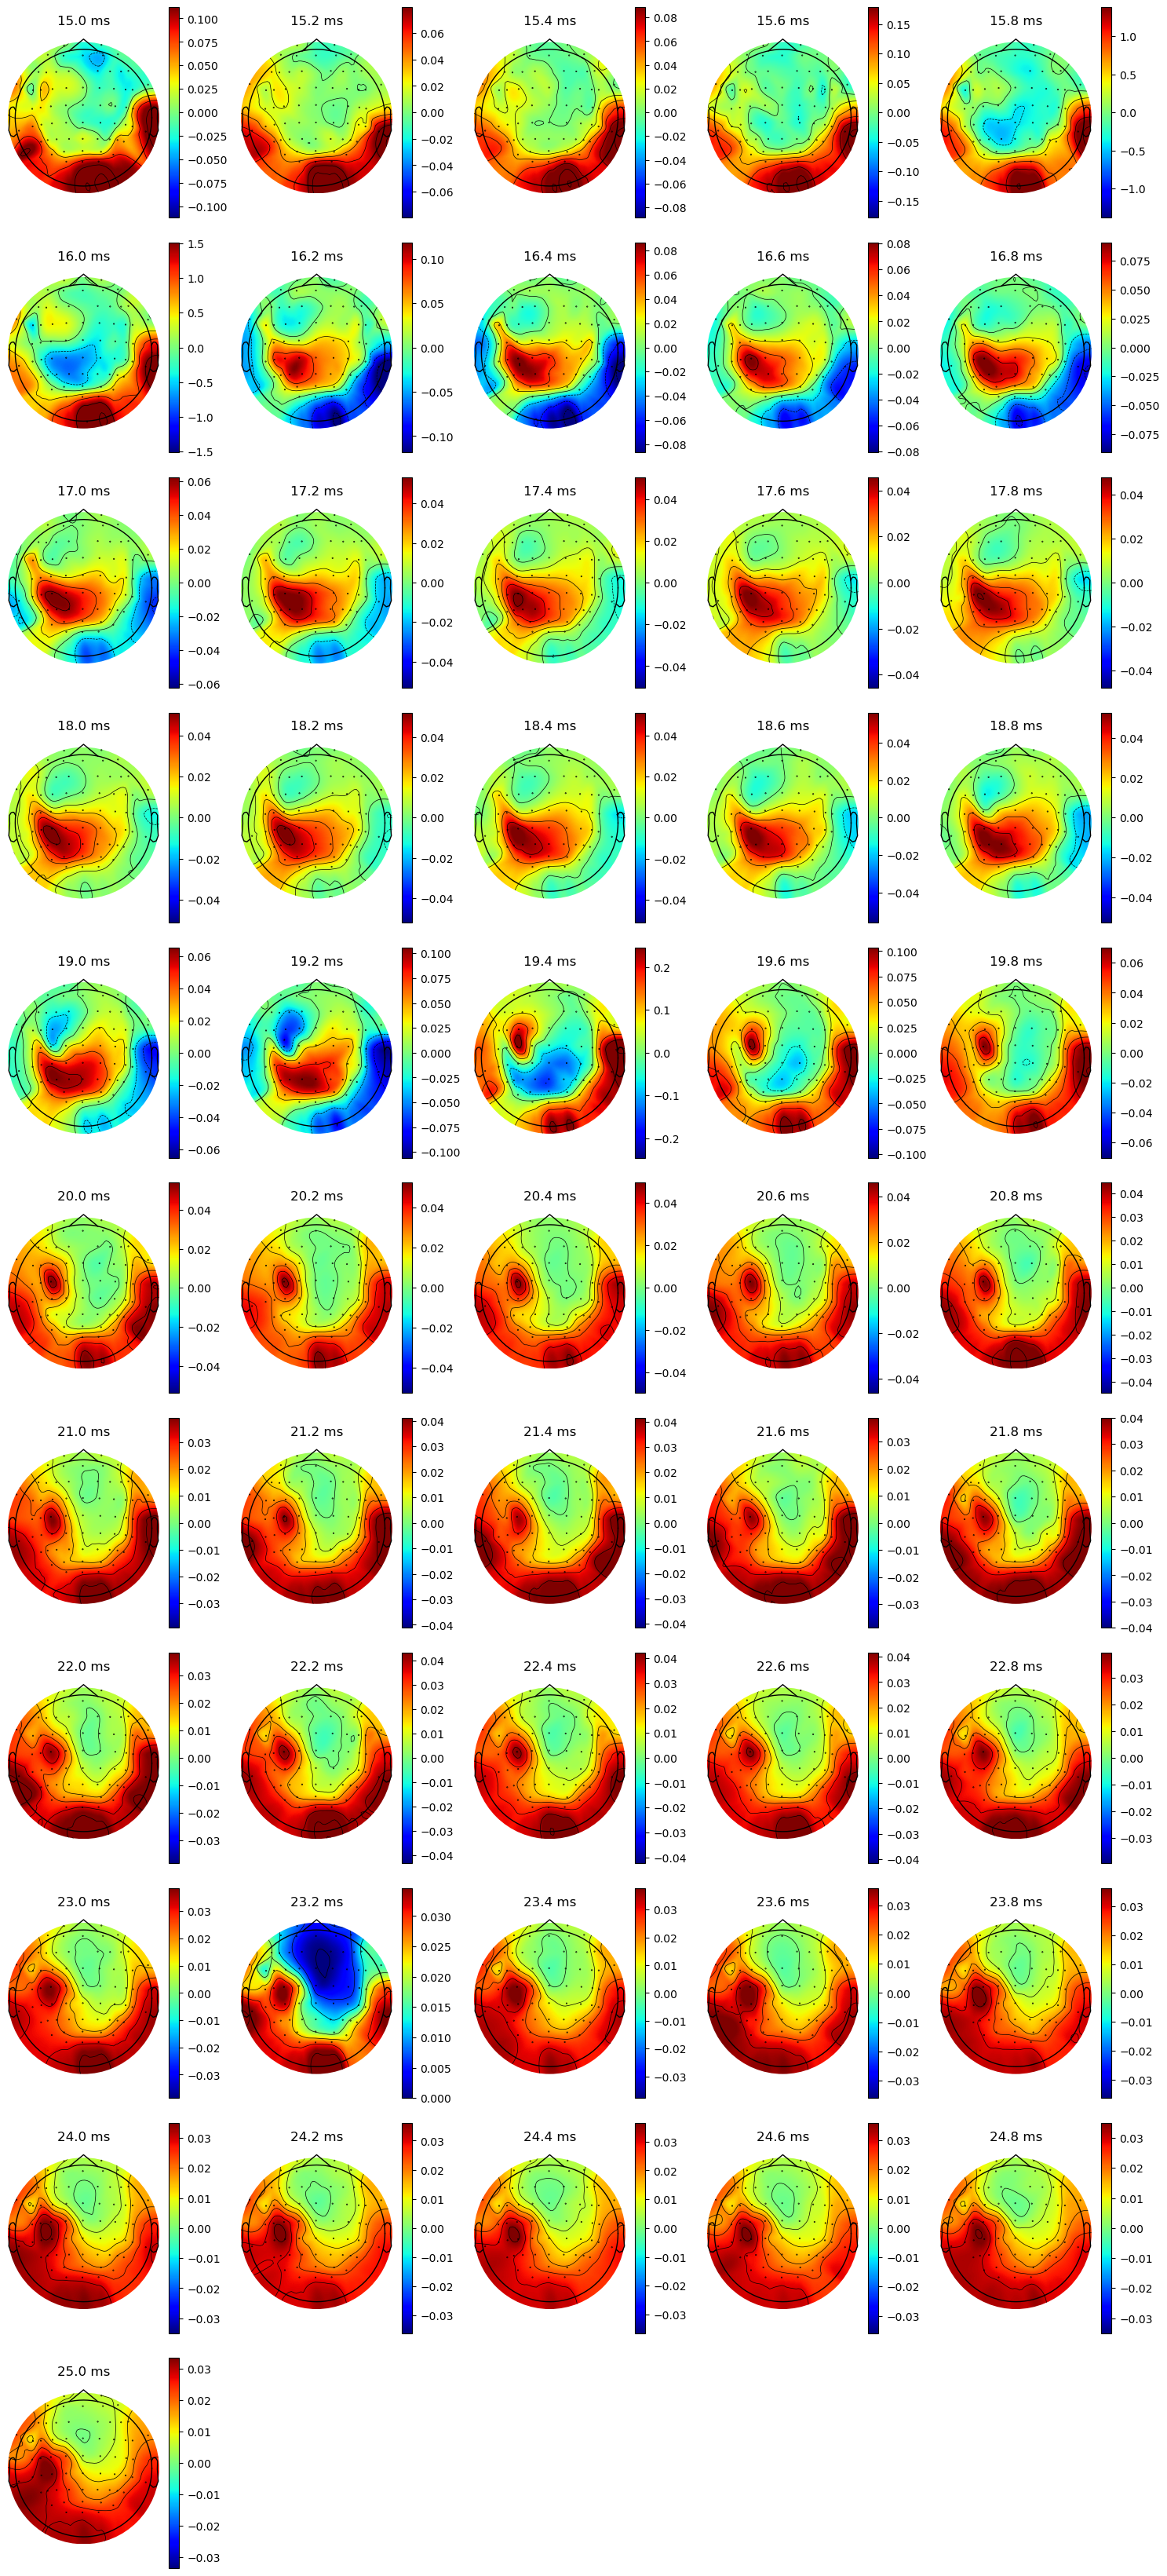

In [11]:
# Topographies for Smits11
plot_topographies(raw)

In [12]:
topo_grid_vals_W_global = None

def compute_topo_grid_W_global(input_matrix=None):
    global topo_grid_vals_W_global

    if input_matrix is None:
        input_matrix = topo_grid_vals_plot_global

    X = np.asarray(input_matrix)

    if X.ndim != 2:
        raise ValueError(
            f"input_matrix deve essere 2D, ma ha shape {X.shape}"
        )

    W_list = []

    for i in range(X.shape[0]):
        # prendo la riga i-esima: shape (63,)
        row = X[i, :]

        # la tratto come matrice riga: shape (1, 63)
        row_matrix = row.reshape(1, -1)

        # pseudoinversa: shape (63, 1)
        W = np.linalg.pinv(row_matrix)

        W_list.append(W)

    # shape finale: (n_topografie, 63, 1)
    topo_grid_vals_W_global = np.stack(W_list, axis=0)

    return topo_grid_vals_W_global

In [13]:
topo_grid_vals_W_global = compute_topo_grid_W_global()

In [14]:
topo_grid_vals_W_2D_global = np.squeeze(topo_grid_vals_W_global, axis=2)

print(topo_grid_vals_plot_global.shape)
print(topo_grid_vals_W_2D_global.shape)

(51, 63)
(51, 63)


In [15]:
i = 22

A = topo_grid_vals_plot_global[i, :]
W = topo_grid_vals_W_2D_global[i, :]



In [16]:
A

array([ 0.03510367,  0.07518973,  0.05413699,  0.11003809,  0.10579384,
        0.12063373,  0.24513035,  0.04646796,  0.14434664, -0.05958346,
       -0.03059541, -0.15374444, -0.10927234,  0.01659679,  0.01354695,
        0.06245139,  0.0838366 , -0.06959174,  0.0907525 ,  0.23268245,
       -0.01244701, -0.13050187, -0.04683235, -0.03478414,  0.14302769,
        0.06991519, -0.00052685, -0.04186134, -0.01870245,  0.05574806,
        0.02111178,  0.05149017,  0.03576228,  0.01440249,  0.05848699,
        0.06515699,  0.07225413,  0.20543916,  0.01034832,  0.04318555,
        0.00903897,  0.0791394 , -0.00999277, -0.1324027 , -0.10168834,
       -0.02284148, -0.09997318, -0.1204191 , -0.05696539,  0.08278849,
        0.01031151, -0.09029259, -0.11666091, -0.07771413,  0.08359225,
       -0.00262266, -0.0701426 , -0.04655029,  0.09155142,  0.01516953,
       -0.00088037, -0.01272895,  0.01569081])

In [17]:
W

array([ 0.07272963,  0.15578205,  0.11216387,  0.22798271,  0.21918925,
        0.24993533,  0.50787397,  0.09627477,  0.29906497, -0.12344815,
       -0.06338918, -0.31853584, -0.22639619,  0.03438611,  0.02806728,
        0.12939008,  0.17369708, -0.14418384,  0.18802581,  0.48208377,
       -0.02578837, -0.27038065, -0.09702974, -0.07206762,  0.29633232,
        0.14485398, -0.00109155, -0.08673053, -0.03874873,  0.11550178,
        0.04374051,  0.10668005,  0.07409417,  0.02983983,  0.12117643,
        0.13499569,  0.14969992,  0.42563967,  0.0214402 ,  0.08947409,
        0.01872741,  0.16396517, -0.02070354, -0.27431888, -0.21068326,
       -0.04732419, -0.2071297 , -0.24949063, -0.11802391,  0.17152555,
        0.02136393, -0.18707295, -0.24170423, -0.16101223,  0.17319083,
       -0.00543376, -0.14532514, -0.09644534,  0.18968105,  0.03142902,
       -0.00182399, -0.02637251,  0.03250905])

In [18]:
def plot_topography_matrix(
    raw,
    matrix=None,
    times=None,
    type="-1",
    n_cols=5,
    cmap="jet",
    title_prefix="Topo",
    save_path=None,
    dpi=300
):
    """
    Plotta topografie a partire da una matrice di valori.

    Parametri
    ---------
    raw : mne.io.Raw
        Oggetto raw MNE, usato per recuperare info e posizioni canali.

    matrix : array-like
        Matrice dei valori da plottare.
        Può essere:
            (n_topografie, 63)
            (n_topografie, 63, 1)
            (63,)

    times : array-like
        Tempi associati alle righe della matrice.
        Se None, prova a usare topo_grid_times_global.

    type : str oppure int
        Se type == "-1" oppure type == -1:
            plotta tutte le topografie.
        Se type >= 0:
            plotta solo la riga indicata.

    title_prefix : str
        Prefisso del titolo, per esempio "v" oppure "W".
    """

    if matrix is None:
        matrix = topo_grid_vals_plot_global

    X = np.asarray(matrix)

    # Caso: vettore singolo di 63 valori
    if X.ndim == 1:
        if X.shape[0] != 63:
            raise ValueError(f"Se X è 1D deve avere 63 valori, ma ha shape {X.shape}")
        X = X.reshape(1, 63)

    # Caso: pseudoinversa salvata come (n, 63, 1)
    if X.ndim == 3:
        if X.shape[2] == 1:
            X = X[:, :, 0]
        else:
            raise ValueError(f"Se X è 3D mi aspetto shape (n, 63, 1), ma ha {X.shape}")

    if X.ndim != 2:
        raise ValueError(f"La matrice deve essere 2D, ma ha shape {X.shape}")

    n_maps, n_channels = X.shape

    if n_channels != 63:
        raise ValueError(f"Mi aspettavo 63 canali, ma la matrice ha {n_channels} colonne")

    # Info canali EEG
    info = raw.info.copy()
    picks = mne.pick_types(info, eeg=True)
    info = mne.pick_info(info, picks)

    montage = mne.channels.make_standard_montage("standard_1020")
    info.set_montage(montage, on_missing="ignore")

    # Gestione tempi
    if times is None:
        if "topo_grid_times_global" in globals() and len(topo_grid_times_global) == n_maps:
            times = topo_grid_times_global
        else:
            times = np.arange(n_maps)

    times = np.asarray(times)

    if len(times) != n_maps:
        raise ValueError(
            f"times deve avere lunghezza {n_maps}, ma ha lunghezza {len(times)}"
        )

    # Interpreto il parametro type
    if str(type) == "-1":
        rows_to_plot = list(range(n_maps))
    else:
        row_index = int(type)

        if row_index < 0 or row_index >= n_maps:
            raise ValueError(
                f"Indice fuori range: {row_index}. Valori ammessi: 0 ... {n_maps - 1}"
            )

        rows_to_plot = [row_index]

    # Caso 1: plotto una sola topografia
    if len(rows_to_plot) == 1:
        i = rows_to_plot[0]
        values = X[i, :]

        fig, ax = plt.subplots(figsize=(6, 5))

        im, _ = mne.viz.plot_topomap(
            values,
            info,
            axes=ax,
            show=False,
            cmap=cmap
        )

        if np.max(np.abs(times)) < 1:
            ax.set_title(f"{title_prefix} - {times[i] * 1000:.1f} ms")
        else:
            ax.set_title(f"{title_prefix} - row {i}")

        plt.colorbar(im, ax=ax)
        plt.tight_layout()

        if save_path is not None:
            fig.savefig(save_path, dpi=dpi, bbox_inches="tight")

        plt.show()

        return fig, ax

    # Caso 2: plotto tutte le topografie
    n_selected = len(rows_to_plot)
    n_rows = int(np.ceil(n_selected / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(15, 3 * n_rows)
    )

    axes = np.array(axes).ravel()

    for ax, i in zip(axes, rows_to_plot):
        values = X[i, :]

        im, _ = mne.viz.plot_topomap(
            values,
            info,
            axes=ax,
            show=False,
            cmap=cmap
        )

        if np.max(np.abs(times)) < 1:
            ax.set_title(f"{title_prefix} - {times[i] * 1000:.1f} ms")
        else:
            ax.set_title(f"{title_prefix} - row {i}")

        plt.colorbar(im, ax=ax)

    for ax in axes[n_selected:]:
        ax.axis("off")

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")

    plt.show()

    return fig, axes

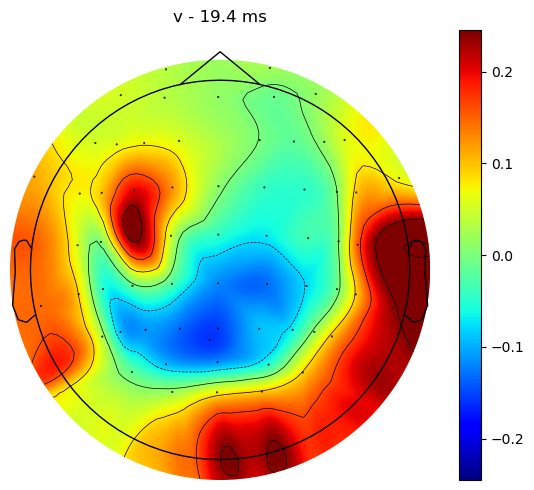

(<Figure size 600x500 with 2 Axes>, <Axes: title={'center': 'v - 19.4 ms'}>)

In [19]:
plot_topography_matrix(
    raw,
    matrix=topo_grid_vals_plot_global,
    times=topo_grid_times_global,
    type="22",
    title_prefix="v"
)

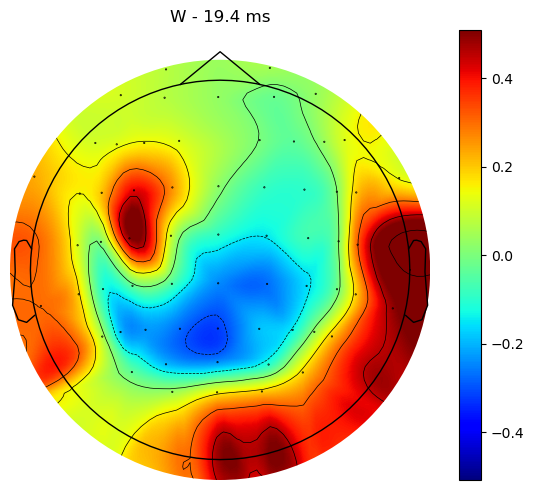

(<Figure size 600x500 with 2 Axes>, <Axes: title={'center': 'W - 19.4 ms'}>)

In [20]:
plot_topography_matrix(
    raw,
    matrix=topo_grid_vals_W_global,
    times=topo_grid_times_global,
    type="22",
    title_prefix="W"
)

In [21]:



# Vettore W: 63 coefficienti
W = np.asarray(W).reshape(-1)

# Matrice EEG filtrata: 63 x 1.524.800
eeg_data = raw.get_data()

# Controllo compatibilità dimensioni
assert W.shape[0] == eeg_data.shape[0]

# Calcolo del vettore FSResult
FSResult = W @ eeg_data

# Verifica del risultato
print("Dimensioni W:", W.shape)
print("Dimensioni EEG:", eeg_data.shape)
print("Dimensioni FSResult:", FSResult.shape)


Dimensioni W: (63,)
Dimensioni EEG: (63, 1524800)
Dimensioni FSResult: (1524800,)


In [22]:
FSResult

array([ 5.06528810e-19,  3.55351613e-06,  1.46265831e-05, ...,
       -1.18794660e-05,  3.19861082e-06, -4.09652064e-19])

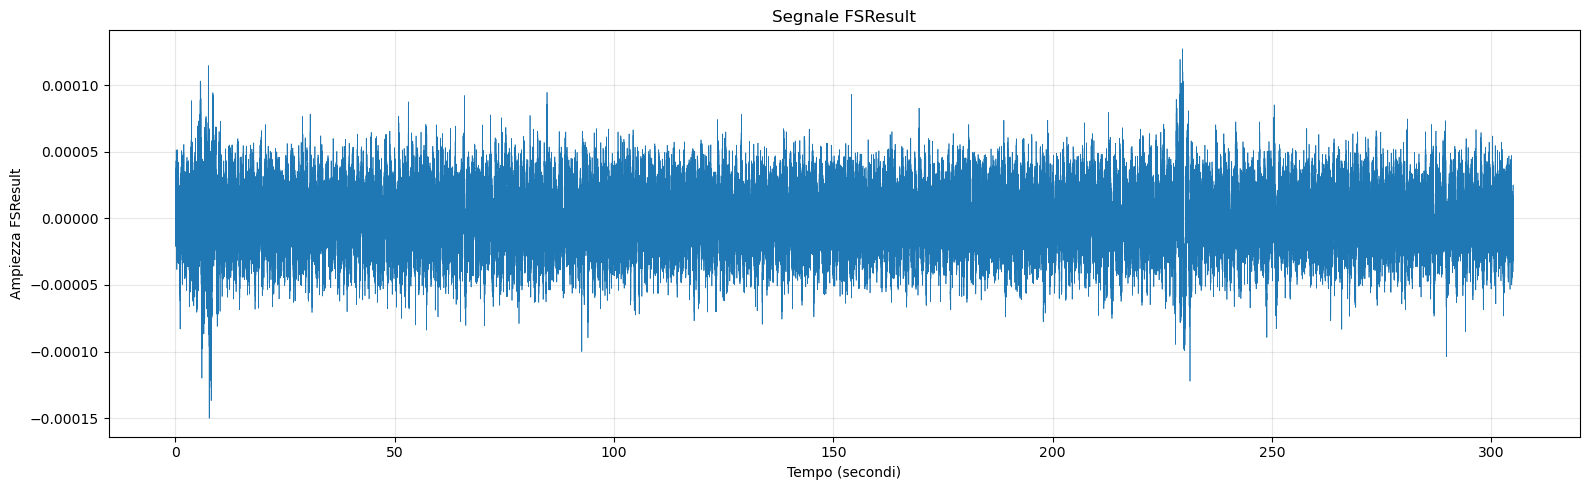

In [23]:


# Frequenza di campionamento EEG
sfreq = raw.info['sfreq']

# Asse temporale in secondi
time = np.arange(len(FSResult)) / sfreq

# Grafico
plt.figure(figsize=(16, 5))
plt.plot(time, FSResult, linewidth=0.5)

plt.title("Segnale FSResult")
plt.xlabel("Tempo (secondi)")
plt.ylabel("Ampiezza FSResult")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:
diff_A_W = A - W
distanza = np.linalg.norm(diff_A_W)

print("Differenza elemento per elemento:", diff_A_W)
print("Distanza euclidea:", distanza)

Differenza elemento per elemento: [-0.03762596 -0.08059232 -0.05802688 -0.11794463 -0.11339541 -0.12930159
 -0.26274363 -0.04980681 -0.15471834  0.06386469  0.03279377  0.1647914
  0.11712385 -0.01778931 -0.01452033 -0.06693869 -0.08986049  0.0745921
 -0.09727331 -0.24940132  0.01334136  0.13987878  0.05019738  0.03728348
 -0.15330462 -0.07493879  0.0005647   0.04486919  0.02004628 -0.05975372
 -0.02262872 -0.05518988 -0.0383319  -0.01543734 -0.06268944 -0.0698387
 -0.07744579 -0.22020052 -0.01109188 -0.04628855 -0.00968844 -0.08482578
  0.01071077  0.14191619  0.10899492  0.0244827   0.10715652  0.12907154
  0.06105851 -0.08873707 -0.01105242  0.09678036  0.12504332  0.0832981
 -0.08959858  0.0028111   0.07518254  0.04989505 -0.09812964 -0.0162595
  0.00094362  0.01364356 -0.01681824]
Distanza euclidea: 0.7446559695277993
